# 32 · Facebook / Instagram before the hand check, and a residual atlas (E81-E83)

No views exist on FB / IG in the Brand24 file. E82 writes estimates for the hand-check sample **before** any view is seen; the last cells of E82 score them once `data/manual/fbig_sample.csv` is filled in. Outputs carry statistics and mention ids only.

In [1]:
import sys, json, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw" / "reach_samples_students.csv").exists())
sys.path.insert(0, str(ROOT / "src"))
pd.set_option("display.width", 250, "display.max_columns", 30, "display.max_rows", 300)
import extra_models as em, eda_utils as eu, account_clusters as ac, author_more as am, fbig_more as fm

In [2]:
f, meta = em.load(ROOT); raw_all = eu.load(ROOT); raw = raw_all.loc[f.index]

## E81 · How FB / IG posts look next to the platforms with views

In [3]:
S81 = fm.structure(raw_all); S81.round(3)

,platform,posts,n,median likes,share 0 reactions,median comments per like,median shares per like,followers known,median followers,median likes per 1k followers,English,median text length
0,facebook,all posts,2500,3.0,0.296,0.000,0.024,0.726,60080.0,0.050,0.713,373.0
1,instagram,all posts,2500,1.0,0.434,0.000,NaN,0.082,7694.0,1.000,0.643,398.5
2,tiktok,all posts,2500,32.0,0.040,0.026,0.023,0.997,1447.0,21.047,0.940,148.5
3,twitter,all posts,2500,0.0,0.642,0.000,0.000,1.000,373.0,0.000,0.975,211.5
4,youtube,all posts,2500,5.0,0.289,0.062,0.000,0.998,27850.0,0.236,0.968,693.0
5,facebook,videos / Reels,470,6.0,0.236,0.000,0.020,0.747,104330.0,0.062,0.794,315.0
6,instagram,videos / Reels,950,1.0,0.443,0.000,NaN,0.087,7613.0,0.996,0.684,330.5


In [4]:
A81 = fm.adversarial(raw_all); A81.pivot_table(index=["target", "columns"], columns="source", values="AUC").round(3)

source                  tiktok  twitter  youtube
target    columns                               
facebook  ll+lc+cpl      0.866    0.813    0.822
          ll+lc+cpl+lf   0.976    0.951    0.886
          ll+lc+cpl+tl   0.895    0.891    0.889
instagram ll+lc+cpl      0.850    0.651    0.657
          ll+lc+cpl+tl   0.862    0.809    0.792

## E82 · Pre-registered estimates for the hand-check sample
Models trained on all posts with views of the source platforms; inputs are the reactions Brand24 recorded. Saved to `data/processed/fbig_preregistered.csv` (mention id + estimates, log10 views).

In [5]:
P82 = fm.preregister(ROOT, f, meta); P82.to_csv(ROOT / "data" / "processed" / "fbig_preregistered.csv", index=False)
P82.groupby("platform").median(numeric_only=True).T.round(2)

platform,facebook,instagram
brand24 reach,3.58,1.30
"ridge likes+comments, TikTok",2.39,1.91
"ridge likes+comments, YouTube",2.39,1.98
"ridge likes+comments, X",2.32,1.60
"ridge likes+comments, all three",2.30,1.79
"CatBoost likes+comments, all three",2.37,1.53
"CatBoost reactions+followers, all three (FB only)",2.70,NaN


In [6]:
# spread between estimates for the same post (max - min over the likes+comments models), log10
cols = [c for c in P82.columns if "likes+comments" in c]; P82.assign(spread=P82[cols].max(1) - P82[cols].min(1)).groupby(["platform", "tier"]).spread.median().round(2).unstack(0)

platform,facebook,instagram
tier,,
0,0.56,0.56
1-10,0.29,0.29
101-1000,0.77,0.64
11-100,0.21,0.21
>1000,1.19,1.13


In [7]:
V82 = fm.implied_vpl(ROOT, P82); V82.round(1)

,platform,estimate,posts,median views per like
0,facebook,brand24 reach,117,135.7
1,facebook,"ridge likes+comments, TikTok",117,31.0
2,facebook,"ridge likes+comments, YouTube",117,28.4
3,facebook,"ridge likes+comments, X",117,39.6
4,facebook,"ridge likes+comments, all three",117,26.6
5,facebook,"CatBoost likes+comments, all three",117,28.5
6,facebook,"CatBoost reactions+followers, all three (FB only)",117,38.3
7,facebook,Brand24 constant,117,100.0
8,instagram,brand24 reach,93,20.0
9,instagram,"ridge likes+comments, TikTok",93,36.9


### Scoring, once the hand check is filled in
Runs only when the sample has at least 10 rows with views. Uses the reactions seen at the check.

In [8]:
path = ROOT / "data" / "manual" / "fbig_sample.csv"; s = pd.read_csv(path, dtype={"mention_id": str}); filled = int((pd.to_numeric(s.views, errors="coerce") > 0).sum()); print("rows with views:", filled)
if filled >= 10:
    Pn = fm.predict_now(ROOT, f, meta, path)
    v2 = pd.read_csv(ROOT / "data" / "processed" / "fbig_preregistered_v2.csv", dtype={"mention_id": str}).drop(columns=["platform", "effective sample share of weights"])
    Pn = Pn.merge(v2, on="mention_id", how="left")   # E88 adaptations, fixed before the check (Brand24 reactions)
    E82, C82 = fm.evaluate(Pn); display(E82.round(3)); display(C82.round(3))
else:
    E82 = C82 = pd.DataFrame()

rows with views: 0


## E83 · Residual atlas: who gets more views than their reactions suggest
Over-performance = true − out-of-fold final model (log10), group mean minus the rest of the platform, brand-bootstrap 95% CI; groups with ≥ 30 posts.

In [9]:
labels = pd.read_csv(ROOT / "data" / "processed" / "mention_labels.csv", dtype={"mention_id": str}).set_index("mention_id").type
lab = pd.Series(labels.reindex(raw.mention_id.astype(str)).values, index=raw.index)
pred = ac.oof(f, meta); d = am.frame(raw, meta, pred); T83 = fm.traits(raw, lab); A83 = fm.atlas(d, T83)
A83[(A83["CI low"] > 0) | (A83["CI high"] < 0)].sort_values(["platform", "over-performance vs rest"]).round(3)

,platform,trait,group,posts,share,over-performance vs rest,CI low,CI high,raw log views vs rest
6,tiktok,country,US,1342,0.539,-0.123,-0.153,-0.092,-0.281
21,tiktok,our type label,unclear,137,0.055,-0.094,-0.157,-0.036,-0.113
23,tiktok,question mark,no,2152,0.864,-0.069,-0.117,-0.022,0.034
19,tiktok,our type label,organic,1179,0.473,-0.050,-0.081,-0.016,0.111
31,tiktok,text length,< 80,593,0.238,-0.048,-0.081,-0.013,-0.028
30,tiktok,text length,80-300,1146,0.460,0.042,0.008,0.074,0.200
7,tiktok,country,GB,183,0.073,0.066,0.003,0.133,-0.065
24,tiktok,question mark,yes,339,0.136,0.069,0.022,0.117,-0.034
4,tiktok,country,other,704,0.283,0.091,0.058,0.127,0.335
20,tiktok,our type label,promo,844,0.339,0.100,0.068,0.134,-0.045


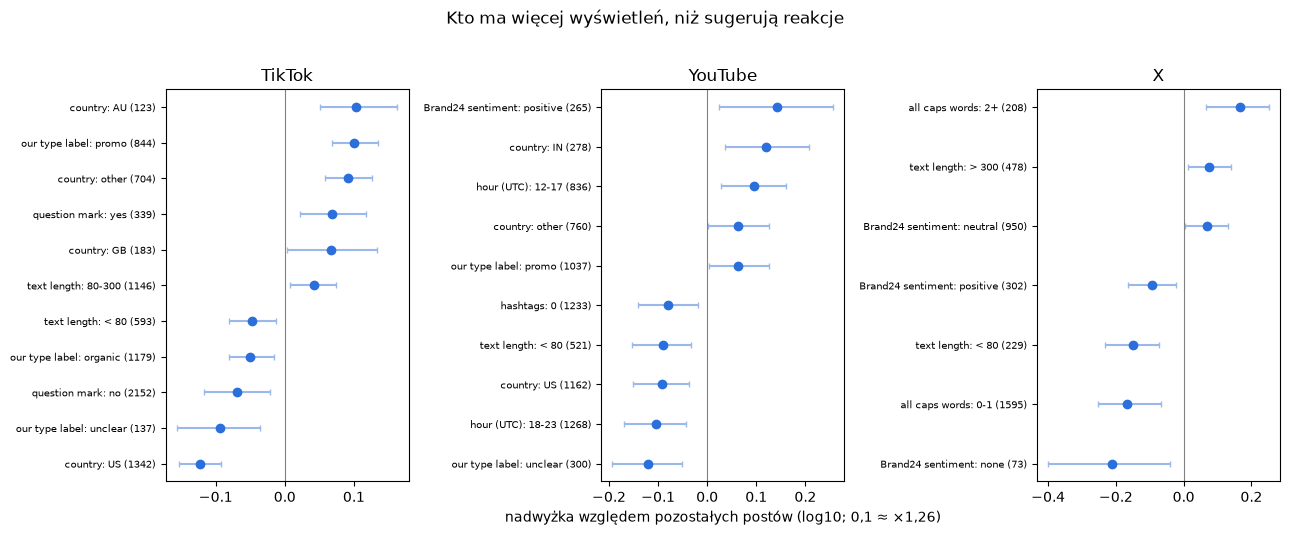

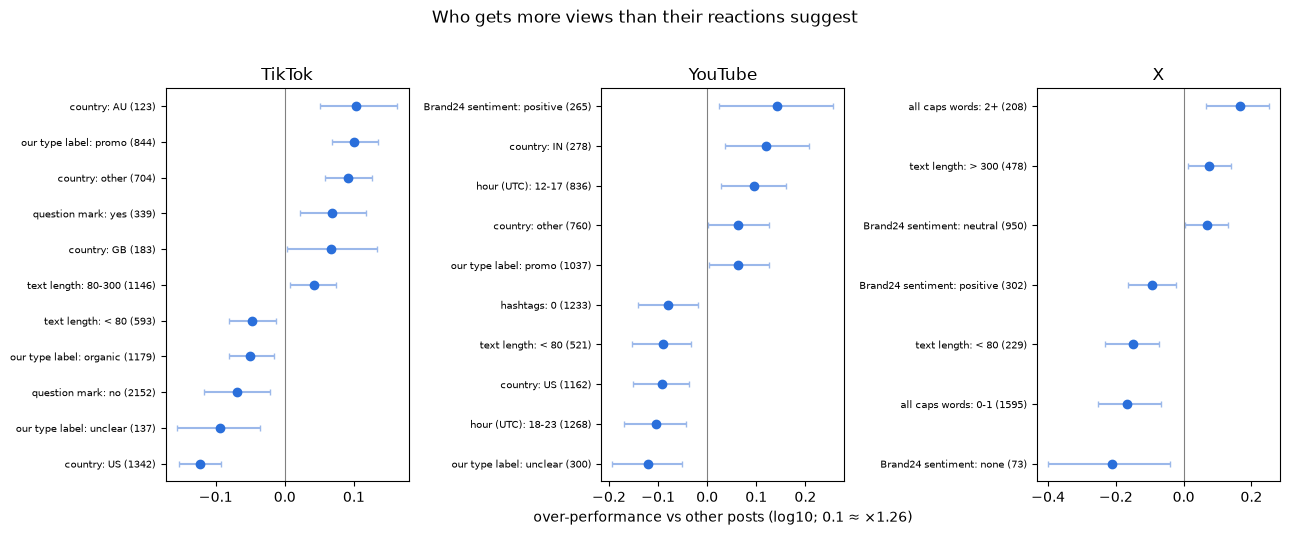

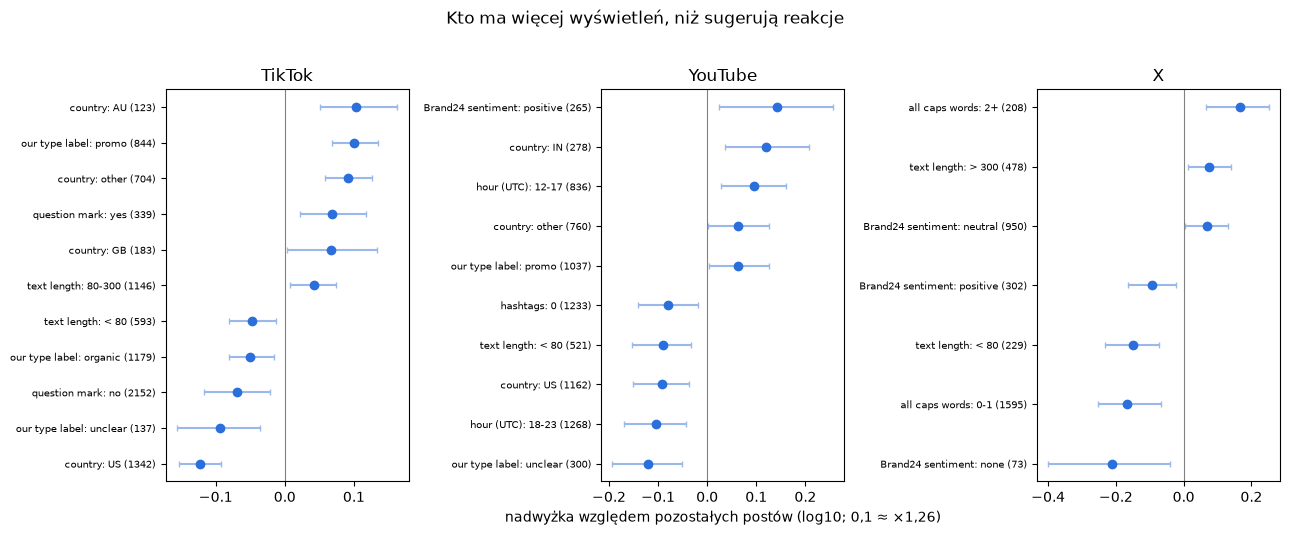

In [10]:
fm.plot_atlas(A83, ROOT / "figures" / "residual_atlas_en.png", "en"); fm.plot_atlas(A83, ROOT / "figures" / "residual_atlas_pl.png", "pl")

## Takeaways
See `docs/en/experiments.md` (E81-E83). Numbers: `data/processed/fbig_more_numbers.json`.

In [11]:
json.dump({"structure": S81.to_dict("records"), "adversarial": A81.to_dict("records"), "preregistered_medians": P82.groupby("platform").median(numeric_only=True).reset_index().to_dict("records"),
           "implied_views_per_like": V82.to_dict("records"), "hand_check_rows": filled, "hand_check_scores": E82.to_dict("records"), "hand_check_calibration": C82.to_dict("records"), "atlas": A83.to_dict("records")},
          open(ROOT / "data" / "processed" / "fbig_more_numbers.json", "w"), indent=1, default=float)